In [1]:
# Cell 01 — Imports
from pathlib import Path
import random, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score, roc_auc_score
)

try:
    from monai.networks.nets import DenseNet121
except ImportError:
    raise ImportError("MONAI is required. Run: pip install monai")


d:\Media\EDU\NUS\GC2\PROJ\GitHub\WIP\multimodalLungDiseaseClassifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Cell 02 — Paths & configuration
DATA_ROOT = Path(r"D:\Media\EDU\NUS\GC2\PROJ\data_test\CT\COVID-CTset\Train&Validation-001")
MODEL_DIR = Path(r"D:\Media\EDU\NUS\GC2\PROJ\GitHub\WIP\multimodalLungDiseaseClassifier\CT\train")
MODEL_PATH = MODEL_DIR / "ct_3d_covid_normal_densenet121.pt"
CACHE_DIR = MODEL_DIR / "volume_cache"

SEED = 42
VOLUME_SIZE = (64, 128, 128)       # Depth, height, width
BATCH_SIZE = 4                     # Reduce to 1 if GPU memory is insufficient
NUM_WORKERS = 0                    # Safe default for Windows/Jupyter
EPOCHS_TUNE = 2                    # Short tuning runs
EPOCHS_FINAL = 10
PATIENCE = 3

# Small, practical hyperparameter search
LEARNING_RATES = [1e-4, 3e-4]
WEIGHT_DECAYS = [1e-5, 1e-4]

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# Cell 03 — Inspect dataset structure
print("DATA_ROOT:", DATA_ROOT)
print("Exists   :", DATA_ROOT.exists())

# Show only a small sample of paths for troubleshooting.
for path in list(DATA_ROOT.rglob("*"))[:40]:
    print(path.relative_to(DATA_ROOT))


DATA_ROOT: D:\Media\EDU\NUS\GC2\PROJ\data_test\CT\COVID-CTset\Train&Validation-001
Exists   : True
137covid_patient100_SR_2_IM00028.tif
137covid_patient100_SR_2_IM00029.tif
137covid_patient100_SR_2_IM00045.tif
137covid_patient100_SR_3_IM00026.tif
137covid_patient100_SR_3_IM00027.tif
137covid_patient100_SR_3_IM00028.tif
137covid_patient101_SR_2_IM00012.tif
137covid_patient101_SR_2_IM00013.tif
137covid_patient101_SR_2_IM00014.tif
137covid_patient101_SR_2_IM00016.tif
137covid_patient101_SR_2_IM00017.tif
137covid_patient101_SR_2_IM00018.tif
137covid_patient101_SR_2_IM00019.tif
137covid_patient101_SR_2_IM00020.tif
137covid_patient101_SR_2_IM00021.tif
137covid_patient101_SR_2_IM00022.tif
137covid_patient101_SR_2_IM00023.tif
137covid_patient101_SR_3_IM00005.tif
137covid_patient101_SR_3_IM00018.tif
137covid_patient101_SR_3_IM00019.tif
137covid_patient101_SR_4_IM00006.tif
137covid_patient101_SR_4_IM00008.tif
137covid_patient101_SR_4_IM00009.tif
137covid_patient101_SR_4_IM00010.tif
137covid_pati

In [4]:
# Cell 04 — Reproducibility & GPU check
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python/PyTorch:", torch.__version__)
print("Device        :", device)
if device.type == "cuda":
    print("GPU           :", torch.cuda.get_device_name(0))
    print("CUDA          :", torch.version.cuda)
    print("VRAM (GB)     :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

Python/PyTorch: 2.14.0+cpu
Device        : cpu


In [5]:
# Cell 05 — Scan TIFF files and identify class


records = []

for path in DATA_ROOT.rglob("*.tif"):

    name = path.stem.lower()

    # Class from filename
    if "covid" in name:
        label_name, label = "covid", 1
    elif "normal" in name:
        label_name, label = "normal", 0
    else:
        continue

    # Extract identifiers needed to rebuild the CT volume
    patient = re.search(r"patient(\d+)", name)
    series  = re.search(r"sr_(\d+)", name)
    image   = re.search(r"im(\d+)", name)

    if not all([patient, series, image]):
        continue

    records.append({
        "patient": f"{label_name}_{patient.group(1)}",
        "label": label,
        "series": f"SR_{series.group(1)}",
        "slice": int(image.group(1)),
        "path": path
    })

images = pd.DataFrame(records)

# Unique patients
patients = (
    images[["patient", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("TIFF images found:", len(images))
print("Patients found   :", len(patients))

print("\nPatient classes:")
print(
    patients["label"]
    .map({0: "NORMAL", 1: "COVID"})
    .value_counts()
)

print("\nSeries:")
print(images["series"].value_counts())

TIFF images found: 12058
Patients found   : 377

Patient classes:
label
NORMAL    282
COVID      95
Name: count, dtype: int64

Series:
series
SR_2    10753
SR_4      666
SR_3      639
Name: count, dtype: int64


In [6]:
# Cell 06 — Select one CT series per patient

# Count available slices for each patient / series
series_counts = (
    images.groupby(["patient", "label", "series"])
    .size()
    .reset_index(name="slices")
)

# Prefer SR_2; otherwise use the series with most slices
def choose_sequence(group):
    sr2 = group[group["series"] == "SR_2"]

    if not sr2.empty:
        return sr2.loc[sr2["slices"].idxmax()]

    return group.loc[group["slices"].idxmax()]


patients = (
    series_counts
    .groupby("patient", group_keys=False)
    .apply(choose_sequence, include_groups=False)
    .reset_index()
)

print("Usable patients:", len(patients))

print("\nClasses:")
print(
    patients["label"]
    .map({0: "NORMAL", 1: "COVID"})
    .value_counts()
)

print("\nSelected series:")
print(patients["series"].value_counts())

print("\nSlice count:")
print(patients["slices"].describe())

display(patients.head())

Usable patients: 377

Classes:
label
NORMAL    282
COVID      95
Name: count, dtype: int64

Selected series:
series
SR_2    377
Name: count, dtype: int64

Slice count:
count    377.000000
mean      28.522546
std       18.358433
min        1.000000
25%       15.000000
50%       27.000000
75%       36.000000
max       78.000000
Name: slices, dtype: float64


,patient,label,series,slices
0,covid_1,1,SR_2,19
1,covid_10,1,SR_2,14
2,covid_100,1,SR_2,3
3,covid_101,1,SR_2,11
4,covid_103,1,SR_2,5


In [7]:
# Cell 07 — Patient-level train / validation / test split
# Split patients BEFORE loading slices to prevent patient leakage.
train_df, temp_df = train_test_split(
    patients, test_size=0.30, stratify=patients["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    counts = df["label"].value_counts().to_dict()
    print(f"{name:10}: {len(df):3} patients | NORMAL={counts.get(0,0):3} | COVID={counts.get(1,0):3}")

Train     : 263 patients | NORMAL=197 | COVID= 66
Validation:  57 patients | NORMAL= 42 | COVID= 15
Test      :  57 patients | NORMAL= 43 | COVID= 14


In [8]:
# Cell 08 — Load, preprocess & cache 3D volumes
def load_volume(patient, series):
    """Load one CT series, preprocess once, then reuse its cached tensor."""

    # Cache key includes volume size so changed preprocessing dimensions create new files.
    cache_path = CACHE_DIR / f"{patient}_{series}_{'x'.join(map(str, VOLUME_SIZE))}.pt"
    if cache_path.exists():
        return torch.load(cache_path, map_location="cpu", weights_only=True)

    # Select and order this patient's TIFF slices.
    rows = images[
        (images["patient"] == patient) &
        (images["series"] == series)
    ].sort_values("slice")
    assert len(rows), f"No slices found for {patient} {series}"

    # Stack ordered 16-bit TIFF slices into [D,H,W].
    volume = np.stack([
        np.array(Image.open(path), dtype=np.float32)
        for path in rows["path"]
    ])

    # Clip extreme intensities, then normalize to 0–1.
    low, high = np.percentile(volume, [1, 99])
    volume = np.clip(volume, low, high)
    if high > low:
        volume = (volume - low) / (high - low)

    # Convert to [1,D,H,W] and standardize volume dimensions.
    volume = torch.from_numpy(volume).unsqueeze(0)
    volume = F.interpolate(
        volume.unsqueeze(0), size=VOLUME_SIZE,
        mode="trilinear", align_corners=False
    ).squeeze(0).float()

    # Save preprocessing result so later epochs/tuning runs avoid TIFF reconstruction.
    torch.save(volume, cache_path)
    return volume


In [9]:
# Cell 09 — 3D Dataset and DataLoaders

class CT3DDataset(Dataset):

    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        volume = load_volume(
            row["patient"],
            row["series"]
        )

        # Mild augmentation: random left/right flip
        if self.augment and random.random() < 0.5:
            volume = torch.flip(volume, dims=[3])

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return volume, label


train_dataset = CT3DDataset(train_df, augment=True)
val_dataset   = CT3DDataset(val_df)
test_dataset  = CT3DDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

Train: 263
Val  : 57
Test : 57


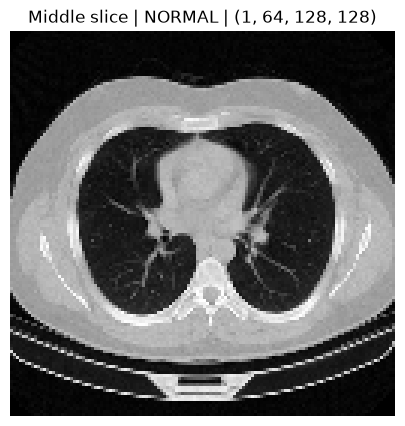

Tensor shape : (1, 64, 128, 128)
Min / Max    : 0.0 / 1.0
Mean / Std   : 0.352 / 0.312


In [10]:
# Cell 10 — Visual preprocessing sanity check

volume, label = train_dataset[0]
mid = volume.shape[1] // 2

# Display middle slice of reconstructed 3D volume
plt.figure(figsize=(5, 5))
plt.imshow(volume[0, mid].numpy(), cmap="gray")
plt.title(
    f"Middle slice | {'COVID' if label.item() else 'NORMAL'} "
    f"| {tuple(volume.shape)}"
)
plt.axis("off")
plt.show()

# Verify preprocessing output
print("Tensor shape :", tuple(volume.shape))
print("Min / Max    :", round(volume.min().item(), 3),
      "/", round(volume.max().item(), 3))
print("Mean / Std   :", round(volume.mean().item(), 3),
      "/", round(volume.std().item(), 3))

In [11]:
# Cell 11 — Model: 3D DenseNet121
def build_model():
    return DenseNet121(
        spatial_dims=3,
        in_channels=1,
        out_channels=2
    ).to(device)

model = build_model()
print("Model: 3D DenseNet121")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Model: 3D DenseNet121
Parameters: 11,244,674


In [12]:
# Cell 12 — Training / validation functions
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss, correct, total = 0.0, 0, 0

    for volumes, labels in loader:
        volumes = volumes.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(volumes)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [13]:
# Cell 13 — Class weighting & hyperparameter tuning
# Weight classes from training patients only; minority COVID errors receive more penalty.
class_counts = train_df["label"].value_counts().sort_index()
class_weights = len(train_df) / (2 * class_counts.values)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Train class counts:", class_counts.to_dict())
print("Class weights     :", class_weights.cpu().numpy())

results = []

# Tune only learning rate and weight decay to keep the search practical.
for lr in LEARNING_RATES:
    for wd in WEIGHT_DECAYS:
        model = build_model()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        start = time.time()

        for _ in range(EPOCHS_TUNE):
            run_epoch(model, train_loader, criterion, optimizer)

        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        results.append({
            "lr": lr, "weight_decay": wd, "val_loss": val_loss,
            "val_accuracy": val_acc, "seconds": time.time() - start
        })

        print(f"lr={lr:g} | wd={wd:g} | val_loss={val_loss:.4f} | val_acc={val_acc:.3f}")
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Select lowest validation loss; accuracy breaks ties.
tuning_results = pd.DataFrame(results).sort_values(
    ["val_loss", "val_accuracy"], ascending=[True, False]
)
display(tuning_results)

best = tuning_results.iloc[0]
BEST_LR = float(best["lr"])
BEST_WD = float(best["weight_decay"])
print("Selected LR:", BEST_LR, "| Weight decay:", BEST_WD)


Train class counts: {0: 197, 1: 66}
Class weights     : [0.6675127 1.9924242]
lr=0.0001 | wd=1e-05 | val_loss=0.2768 | val_acc=0.895
lr=0.0001 | wd=0.0001 | val_loss=0.2365 | val_acc=0.930
lr=0.0003 | wd=1e-05 | val_loss=0.2073 | val_acc=0.965
lr=0.0003 | wd=0.0001 | val_loss=0.1623 | val_acc=0.965


,lr,weight_decay,val_loss,val_accuracy,seconds
3,0.0003,0.00010,0.162341,0.964912,651.898968
2,0.0003,0.00001,0.207304,0.964912,655.097002
1,0.0001,0.00010,0.236496,0.929825,662.732009
0,0.0001,0.00001,0.276821,0.894737,737.305247


Selected LR: 0.0003 | Weight decay: 0.0001


In [14]:
# Cell 14 — Final training with early stopping
model = build_model()
optimizer = torch.optim.AdamW(model.parameters(), lr=BEST_LR, weight_decay=BEST_WD)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)

history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}
best_loss = float("inf")
wait = 0

for epoch in range(1, EPOCHS_FINAL + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02}/{EPOCHS_FINAL} | train {train_loss:.4f}/{train_acc:.3f} | val {val_loss:.4f}/{val_acc:.3f}")

    if val_loss < best_loss:
        best_loss, wait = val_loss, 0
        torch.save(model.state_dict(), MODEL_PATH)
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping.")
            break

print("Best model saved:", MODEL_PATH)

Epoch 01/10 | train 0.5189/0.795 | val 0.4400/0.912
Epoch 02/10 | train 0.4556/0.840 | val 0.2056/0.947
Epoch 03/10 | train 0.4309/0.871 | val 0.6779/0.789
Epoch 04/10 | train 0.3925/0.890 | val 0.1352/0.965
Epoch 05/10 | train 0.3722/0.886 | val 0.2629/0.877
Epoch 06/10 | train 0.3767/0.897 | val 0.1867/0.930
Epoch 07/10 | train 0.2906/0.916 | val 0.1565/0.965
Early stopping.
Best model saved: D:\Media\EDU\NUS\GC2\PROJ\GitHub\WIP\multimodalLungDiseaseClassifier\CT\train\ct_3d_covid_normal_densenet121.pt


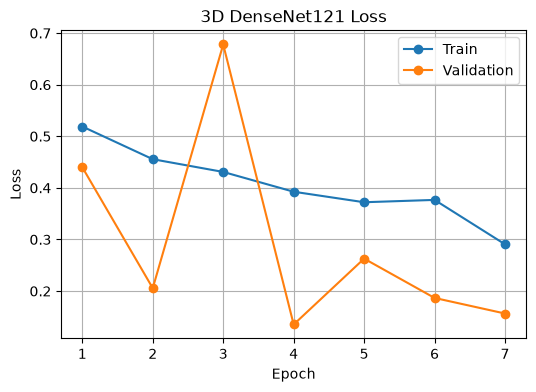

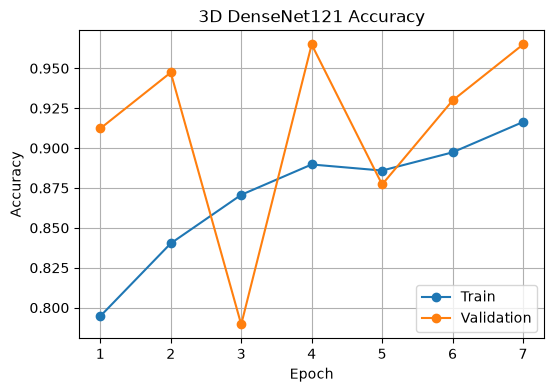

In [15]:
# Cell 15 — Plot training history
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(6,4))
plt.plot(epochs, history["train_loss"], marker="o", label="Train")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("3D DenseNet121 Loss")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(6,4))
plt.plot(epochs, history["train_acc"], marker="o", label="Train")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("3D DenseNet121 Accuracy")
plt.legend(); plt.grid(True); plt.show()

              precision    recall  f1-score   support

      NORMAL       0.98      0.95      0.96        43
       COVID       0.87      0.93      0.90        14

    accuracy                           0.95        57
   macro avg       0.92      0.94      0.93        57
weighted avg       0.95      0.95      0.95        57

Balanced accuracy: 0.94
ROC-AUC          : 0.99


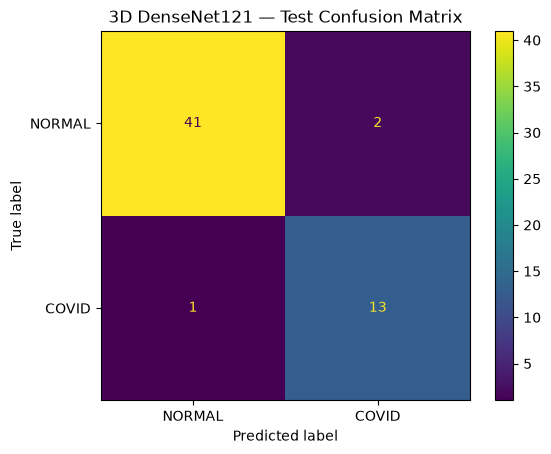

In [ ]:
# Cell 16 — Independent test evaluation
# Reload the best validation-loss checkpoint before touching the test set.
model = build_model()
model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
model.eval()

y_true, y_pred, y_prob = [], [], []

# Collect labels, predictions and COVID probabilities for all unseen test patients.
with torch.no_grad():
    for volumes, labels in test_loader:
        outputs = model(volumes.to(device))
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(outputs.argmax(1).cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

# Report class-level metrics plus imbalance-aware summary metrics.
print(classification_report(y_true, y_pred, target_names=["NORMAL", "COVID"], digits=2))
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.2f}")
print(f"ROC-AUC          : {roc_auc_score(y_true, y_prob):.2f}")

# Visualize final patient-level classification errors.
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "COVID"]).plot()
plt.title("3D DenseNet121 — Test Confusion Matrix")
plt.show()


In [17]:
# Cell 17 — Results summary
# Calculate concise final metrics from the untouched test set.
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
accuracy = (tp + tn) / len(y_true)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_prob)
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

print("3D DenseNet121 — TEST RESULTS")
print(f"Test patients     : {len(y_true)}")
print(f"Accuracy          : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Balanced accuracy : {balanced_acc:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"Precision (COVID) : {precision:.4f}")
print(f"Recall (COVID)    : {recall:.4f}")
print(f"Specificity       : {specificity:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"TN / FP / FN / TP : {tn} / {fp} / {fn} / {tp}")
print(f"Best LR / WD      : {BEST_LR:g} / {BEST_WD:g}")


3D DenseNet121 — TEST RESULTS
Test patients     : 57
Accuracy          : 0.9474 (94.74%)
Balanced accuracy : 0.9410
ROC-AUC           : 0.9917
Precision (COVID) : 0.8667
Recall (COVID)    : 0.9286
Specificity       : 0.9535
F1-score          : 0.8966
TN / FP / FN / TP : 41 / 2 / 1 / 13
Best LR / WD      : 0.0003 / 0.0001


In [18]:
# Cell 18 — Test one random NORMAL and one random COVID patient

# Randomly select one patient from each class
samples = [
    test_df[test_df["label"] == 0].sample(n=1).iloc[0],
    test_df[test_df["label"] == 1].sample(n=1).iloc[0]
]

model.eval()

for row in samples:

    # Load patient's selected 3D CT series
    volume = load_volume(
        row["patient"],
        row["series"]
    ).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        probabilities = torch.softmax(
            model(volume),
            dim=1
        )[0].cpu().numpy()

    prediction = probabilities.argmax()

    print("=" * 45)
    print("Patient    :", row["patient"])
    print("Series     :", row["series"])
    print("True label :", "COVID" if row["label"] == 1 else "NORMAL")
    print("Prediction :", "COVID" if prediction == 1 else "NORMAL")
    print(f"Normal prob: {probabilities[0]:.4f}")
    print(f"COVID prob : {probabilities[1]:.4f}")

Patient    : normal_340
Series     : SR_2
True label : NORMAL
Prediction : NORMAL
Normal prob: 0.9799
COVID prob : 0.0201
Patient    : covid_130
Series     : SR_2
True label : COVID
Prediction : COVID
Normal prob: 0.0298
COVID prob : 0.9702


### Notes
- One patient = one sample; patient-level splitting prevents slice leakage.
- One preferred series (`SR_2`, then fallback) is used per patient.
- Class-weighted loss reduces bias from the NORMAL/COVID class imbalance.
- Balanced accuracy and ROC-AUC complement ordinary accuracy on skewed classes.
- Preprocessed volumes are cached to disk; the first pass is slower, later epochs/runs reuse them.
- `VOLUME_SIZE=(64,128,128)` and `BATCH_SIZE=2` are conservative GPU starting values.
- Source: COVID-CTset — https://github.com/mr7495/COVID-CTset
